In [1]:
import os
import matplotlib.pyplot as plt
import pytorch_lightning as pl
import torch
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
from dataset import SegmentationDataset
from model import LeafModel
from torchvision.transforms import v2
from pytorch_lightning.loggers import MLFlowLogger
from pytorch_lightning.callbacks.early_stopping import EarlyStopping
from pytorch_lightning.callbacks import ModelCheckpoint
import shutil
import tempfile

# Enable Tensor Cores on A100 for ~2x speed boost
torch.set_float32_matmul_precision('medium')

%matplotlib inline
%load_ext autoreload
%autoreload 2

/mnt/SFS-8Bv5kQHZ/ml-platform/leaf-segmentation-pytorch/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Create datasets and dataloaders

In [ ]:
# We have to resize the images and masks to a fixed size for batching

transforms = v2.Compose([
    v2.Resize((256, 256), interpolation=v2.InterpolationMode.NEAREST),
])

train_dataset = SegmentationDataset(root_dir='roboflow/train/', transform=transforms, target_transform=transforms)
val_dataset = SegmentationDataset(root_dir='roboflow/valid/', transform=transforms, target_transform=transforms)
test_dataset = SegmentationDataset(root_dir='roboflow/test/', transform=transforms, target_transform=transforms)

print(f'Train samples: {len(train_dataset)}')
print(f'Validation samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')

n_cpu = os.cpu_count() or 8
# Increased batch size from 32 to 64 for fewer iterations and better GPU utilization
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=n_cpu - 2, pin_memory=True, persistent_workers=True)
valid_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=n_cpu - 2, pin_memory=True, persistent_workers=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=n_cpu - 2, pin_memory=True, persistent_workers=True)

Loading dataset from roboflow/train/...
loading annotations into memory...
Done (t=0.45s)
creating index...
index created!
Loading pre-computed masks from cache...
Done (t=0.45s)
creating index...
index created!
Loading pre-computed masks from cache...
Dataset ready with 350 samples! Cache size: 87.5 MB
Loading dataset from roboflow/valid/...
loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
Loading pre-computed masks from cache...
Dataset ready with 350 samples! Cache size: 87.5 MB
Loading dataset from roboflow/valid/...
loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
Loading pre-computed masks from cache...
Dataset ready with 100 samples! Cache size: 25.0 MB
Loading dataset from roboflow/test/...
loading annotations into memory...
Dataset ready with 100 samples! Cache size: 25.0 MB
Loading dataset from roboflow/test/...
loading annotations into memory...
Done (t=0.87s)
creating index...
index created!
Loading pre-com

Visualize a few samples from the dataset to ensure that images and masks are loaded correctly.

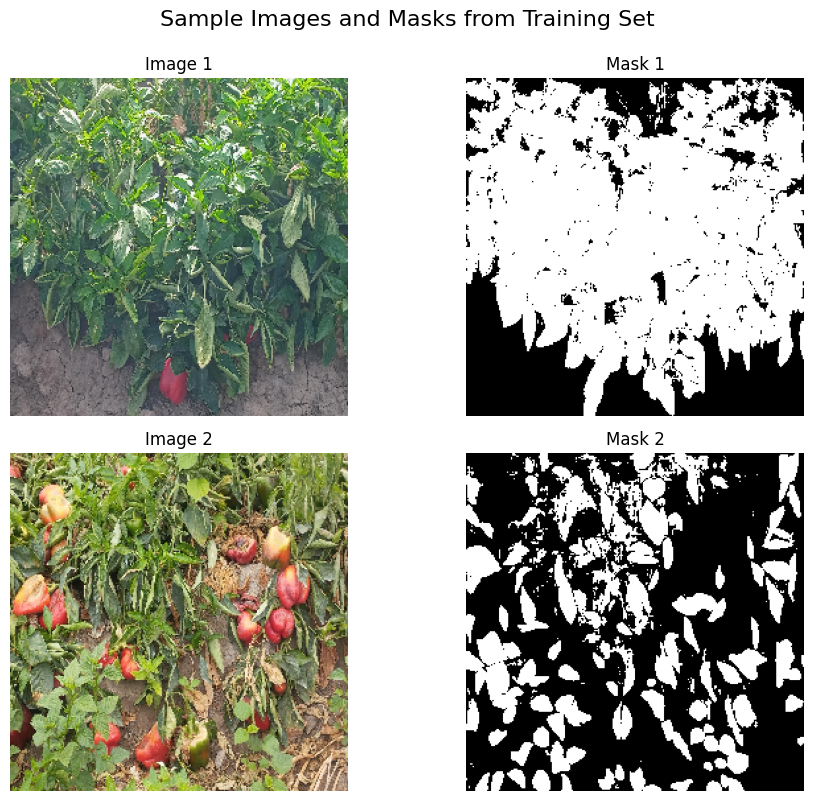

In [12]:
num_samples = 2

figure, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))
figure.suptitle('Sample Images and Masks from Training Set', fontsize=16, y=0.995)

for i in range(num_samples):
    img_id = torch.randint(0, len(train_dataset), (1,)).item()
    image, mask = train_dataset[img_id]
    
    # Display image
    axes[i, 0].imshow(image.permute(1, 2, 0))
    axes[i, 0].set_title(f'Image {i+1}')
    axes[i, 0].axis('off')
    
    # Display mask
    axes[i, 1].imshow(mask.squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {i+1}')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Enable mlflow logging

In [13]:
# Create temporary directory for local artifacts
# temp_dir = tempfile.mkdtemp()

mlflow_logger = MLFlowLogger(
    experiment_name="leaf_segmentation_pepper",
    # tracking_uri="http://localhost:5011",
    log_model=True,
    # save_dir=temp_dir,  # Temporary local storage
)

Configure model

In [14]:
EPOCHS = 300
T_MAX = EPOCHS * len(train_dataloader)
OUT_CLASSES = 1
model = LeafModel("FPN", "resnet34", in_channels=3, out_classes=1, t_max=T_MAX)

# Optional: Compile model for faster training (PyTorch 2.0+)
# Uncomment if you have PyTorch 2.0 or later
# model = torch.compile(model)

Set hyperparameters and start training loop

In [15]:
# Early stopping callback - monitors validation loss
early_stop_callback = EarlyStopping(
    monitor="val_loss",
    patience=10,  # Increased patience for 300 epochs
    mode="min",
    verbose=True
)

# Model checkpoint callback - only saves best model to MLflow
checkpoint_callback = ModelCheckpoint(
    # dirpath=temp_dir,  # Temporary local storage
    filename="best-model",
    monitor="val_loss",
    mode="min",
    save_top_k=1,  # Only keep the best model
    save_last=False,  # Don't save the last model
    every_n_epochs=1,  # Check only at end of each epoch (not every batch)
)

trainer = pl.Trainer(
    max_epochs=EPOCHS,
    logger=mlflow_logger,
    callbacks=[early_stop_callback, checkpoint_callback],
    enable_checkpointing=True,
)

trainer.fit(
    model,
    train_dataloaders=train_dataloader,
    val_dataloaders=valid_dataloader,
)

# Clean up temporary directory after training
# shutil.rmtree(temp_dir, ignore_errors=True)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name    | Type     | Params | Mode  | FLOPs
-----------------------------------------------------
0 | model   | FPN      | 23.2 M | train | 0    
1 | loss_fn | DiceLoss | 0      | train | 0    
-----------------------------------------------------
23.2 M    Trainable params
0         Non-trainable params
23.2 M    Total params
92.622    Total estimated model params size (MB)
175       Modules in train mode
0         Modules in eval mode
0         Total Flops

  |

/mnt/SFS-8Bv5kQHZ/ml-platform/leaf-segmentation-pytorch/venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:317: The number of training batches (1) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Epoch 0: 100%|██████████| 1/1 [01:37<00:00,  0.01it/s, v_num=3e67, val_loss=0.328, valid_per_image_iou=0.503, valid_dataset_iou=0.503, valid_accuracy=0.506, valid_f1_score=0.669, train_loss=0.509]

Metric val_loss improved. New best score: 0.328


Epoch 1:   0%|          | 0/1 [00:00<?, ?it/s, v_num=3e67, val_loss=0.328, valid_per_image_iou=0.503, valid_dataset_iou=0.503, valid_accuracy=0.506, valid_f1_score=0.669, train_loss=0.509]        


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/mnt/SFS-8Bv5kQHZ/ml-platform/leaf-segmentation-pytorch/venv/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Validation Metrics

In [9]:
valid_metrics = trainer.validate(model, dataloaders=valid_dataloader, verbose=False)
print(valid_metrics)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Validation DataLoader 0: 100%|██████████| 4/4 [00:01<00:00,  2.92it/s]


VALIDATE Profiler Report

----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|  Action                                                                                                                                                               	|  Mean duration (s)	|  Num calls      	|  Total time (s) 	|  Percentage %   	|
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|  Total                                                                                                                                                                	|  -  

[{'val_loss': 0.19820745289325714, 'valid_per_image_iou': 0.6481155157089233, 'valid_dataset_iou': 0.673193633556366, 'valid_accuracy': 0.7940463423728943, 'valid_f1_score': 0.804681122303009}]


Visualize predictions

[W1219 12:23:05.961716251 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


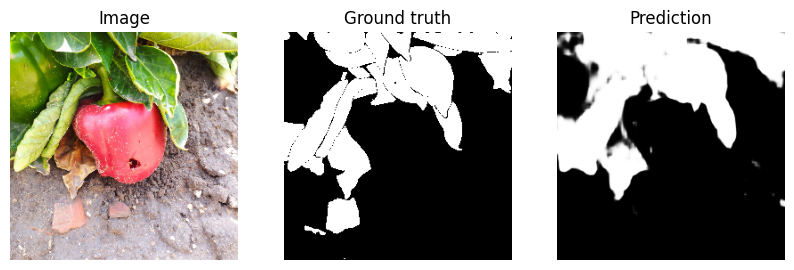

[W1219 12:23:06.568932715 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


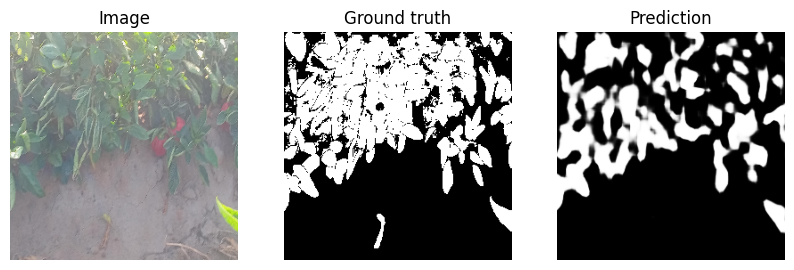

[W1219 12:23:06.029949622 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


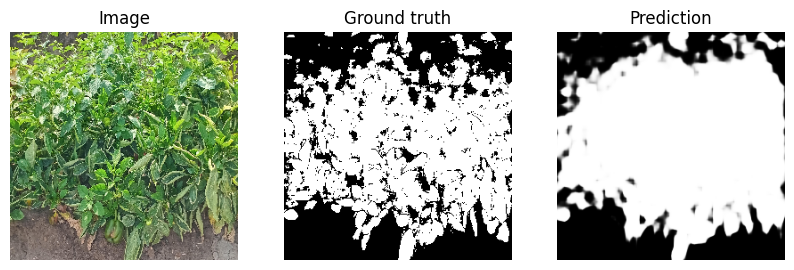

[W1219 12:23:07.324042433 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


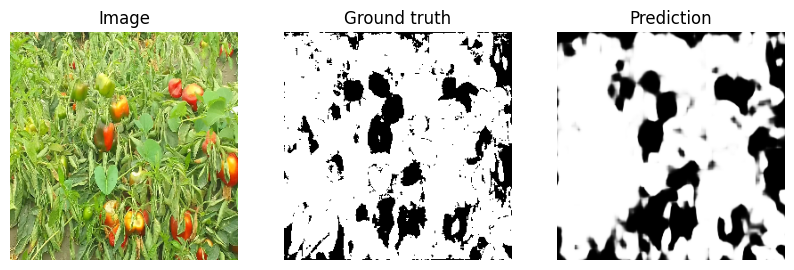

[W1219 12:23:07.770147460 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


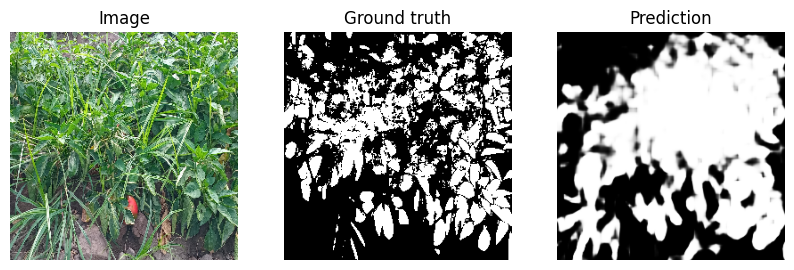

[W1219 12:23:07.229372778 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


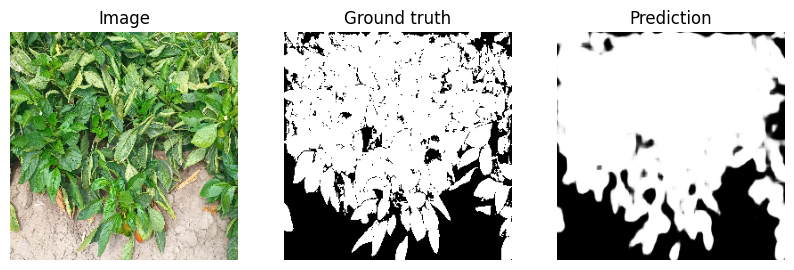

[W1219 12:23:08.675699504 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


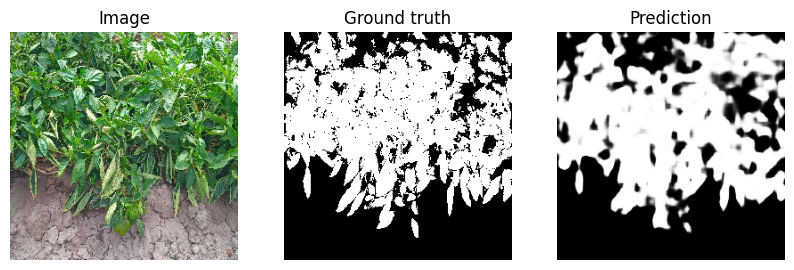

[W1219 12:23:08.974809795 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


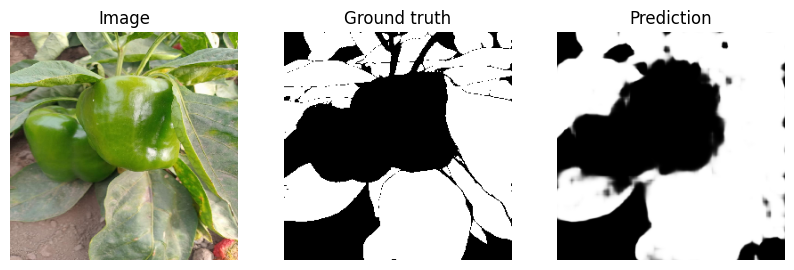

[W1219 12:23:09.380229228 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


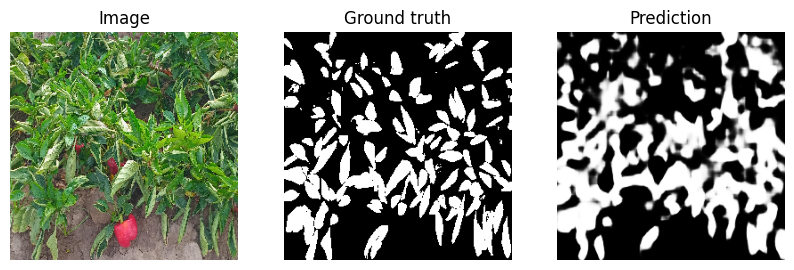

[W1219 12:23:09.698138111 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


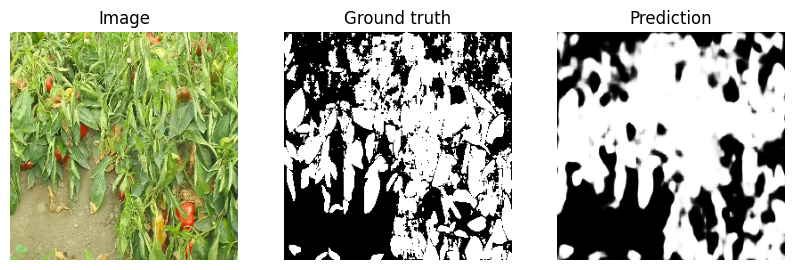

In [10]:
import random

num_samples = 10
# Get all test samples
all_samples = list(range(len(test_dataset)))
random_indices = random.sample(all_samples, min(num_samples, len(all_samples)))

for idx in random_indices:
    image, gt_mask = test_dataset[idx]
    
    with torch.inference_mode():
        model.eval()
        logits = model(image.unsqueeze(0))
    
    pr_mask = logits.sigmoid().squeeze()
    
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gt_mask.squeeze(), cmap='gray')
    plt.title("Ground truth")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pr_mask.detach().numpy(), cmap='gray')
    plt.title("Prediction")
    plt.axis("off")
    plt.show()